<a href="https://colab.research.google.com/github/raghavxi1/fitness-engagement-analysis/blob/main/notebooks/02_sql_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import files
import pandas as pd, sqlite3
files.upload()   # select daily_clean.csv and steps_clean.csv

conn = sqlite3.connect("fitness.db")
pd.read_csv("daily_clean.csv").to_sql("daily_activity", conn, if_exists="replace", index=False)
pd.read_csv("steps_clean.csv").to_sql("hourly_steps", conn, if_exists="replace", index=False)

def q(sql): return pd.read_sql(sql, conn)

q("SELECT COUNT(*) AS rows, COUNT(DISTINCT Id) AS users FROM daily_activity")

Saving steps_clean.csv to steps_clean.csv
Saving daily_clean.csv to daily_clean.csv


,rows,users
0,1373,35


In [5]:
q("""
SELECT Id,
       COUNT(*) AS days_recorded,
       SUM(CASE WHEN LikelyNotWorn = 0 THEN 1 ELSE 0 END) AS active_days,
       ROUND(100.0 * SUM(CASE WHEN LikelyNotWorn = 0 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_active
FROM daily_activity
GROUP BY Id
ORDER BY active_days DESC
""")

,Id,days_recorded,active_days,pct_active
0,1624580081,49,49,100.0
1,4020332650,62,48,77.4
2,1503960366,49,48,98.0
3,4445114986,45,45,100.0
4,6962181067,44,44,100.0
5,4702921684,45,43,95.6
6,8877689391,42,42,100.0
7,8378563200,42,42,100.0
8,5553957443,42,42,100.0
9,4558609924,42,42,100.0


In [6]:
q("""
SELECT strftime('%W', ActivityDate) AS week_no,
       COUNT(DISTINCT Id) AS users_active
FROM daily_activity
WHERE LikelyNotWorn = 0
GROUP BY week_no
ORDER BY week_no
""")

,week_no,users_active
0,10,1
1,11,2
2,12,4
3,13,32
4,14,33
5,15,33
6,16,32
7,17,31
8,18,29
9,19,24


In [7]:
q("""
SELECT DayOfWeek,
       ROUND(AVG(TotalSteps), 0) AS avg_steps,
       ROUND(AVG(Calories), 0) AS avg_calories
FROM daily_activity
WHERE LikelyNotWorn = 0
GROUP BY DayOfWeek
ORDER BY avg_steps DESC
""")

,DayOfWeek,avg_steps,avg_calories
0,Saturday,8667.0,2423.0
1,Monday,8389.0,2368.0
2,Wednesday,8122.0,2356.0
3,Thursday,8099.0,2295.0
4,Tuesday,7891.0,2258.0
5,Friday,7773.0,2351.0
6,Sunday,7457.0,2301.0


In [8]:
q("""
SELECT Hour, ROUND(AVG(StepTotal), 0) AS avg_steps
FROM hourly_steps
GROUP BY Hour
ORDER BY Hour
""")

,Hour,avg_steps
0,0,43.0
1,1,22.0
2,2,14.0
3,3,7.0
4,4,11.0
5,5,35.0
6,6,148.0
7,7,283.0
8,8,396.0
9,9,431.0


In [9]:
q("""
WITH user_avg AS (
    SELECT Id, AVG(TotalSteps) AS avg_steps
    FROM daily_activity
    WHERE LikelyNotWorn = 0
    GROUP BY Id
)
SELECT CASE
         WHEN avg_steps >= 10000 THEN '4. Highly active (10k+)'
         WHEN avg_steps >= 7500  THEN '3. Active (7.5k-10k)'
         WHEN avg_steps >= 5000  THEN '2. Lightly active (5k-7.5k)'
         ELSE '1. Low activity (<5k)'
       END AS segment,
       COUNT(*) AS users,
       ROUND(AVG(avg_steps), 0) AS segment_avg_steps
FROM user_avg
GROUP BY segment
ORDER BY segment
""")

,segment,users,segment_avg_steps
0,1. Low activity (<5k),10,3817.0
1,2. Lightly active (5k-7.5k),8,6394.0
2,3. Active (7.5k-10k),9,8621.0
3,4. Highly active (10k+),8,12348.0


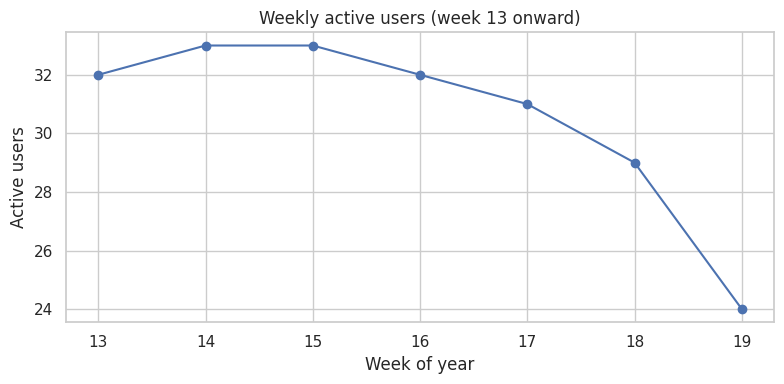

In [10]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

wk = q("""SELECT CAST(strftime('%W', ActivityDate) AS INT) AS week_no,
          COUNT(DISTINCT Id) AS users_active
          FROM daily_activity WHERE LikelyNotWorn = 0
          GROUP BY week_no""")
wk = wk[wk.week_no >= 13]   # exclude onboarding weeks

plt.figure(figsize=(8,4))
plt.plot(wk.week_no, wk.users_active, marker="o")
plt.title("Weekly active users (week 13 onward)")
plt.xlabel("Week of year"); plt.ylabel("Active users")
plt.tight_layout(); plt.savefig("weekly_active_users.png", dpi=150); plt.show()

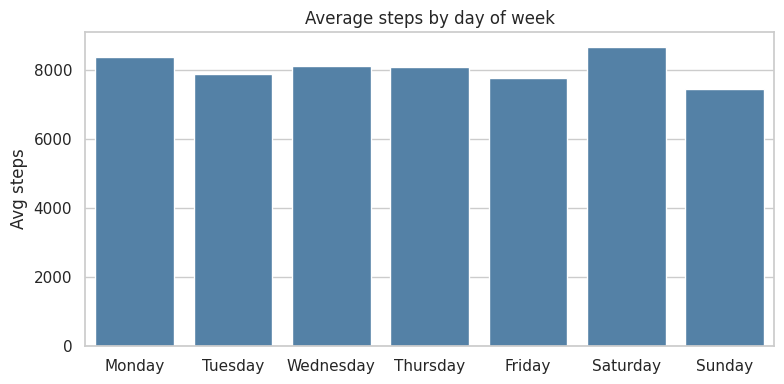

In [11]:
dow = q("""SELECT DayOfWeek, AVG(TotalSteps) AS avg_steps
           FROM daily_activity WHERE LikelyNotWorn = 0 GROUP BY DayOfWeek""")
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow["DayOfWeek"] = pd.Categorical(dow["DayOfWeek"], order, ordered=True)
dow = dow.sort_values("DayOfWeek")

plt.figure(figsize=(8,4))
sns.barplot(data=dow, x="DayOfWeek", y="avg_steps", color="steelblue")
plt.title("Average steps by day of week")
plt.xlabel(""); plt.ylabel("Avg steps")
plt.tight_layout(); plt.savefig("steps_by_day.png", dpi=150); plt.show()

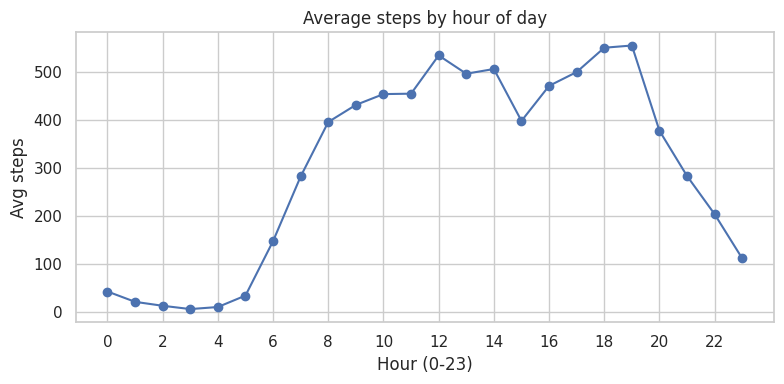

In [12]:
hr = q("SELECT Hour, AVG(StepTotal) AS avg_steps FROM hourly_steps GROUP BY Hour")
plt.figure(figsize=(8,4))
plt.plot(hr.Hour, hr.avg_steps, marker="o")
plt.title("Average steps by hour of day")
plt.xlabel("Hour (0-23)"); plt.ylabel("Avg steps"); plt.xticks(range(0,24,2))
plt.tight_layout(); plt.savefig("steps_by_hour.png", dpi=150); plt.show()

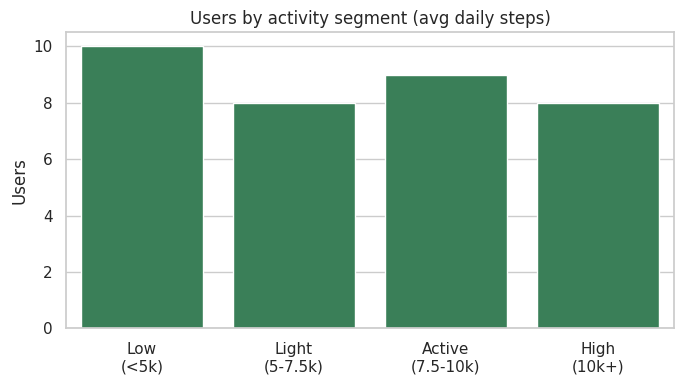

In [13]:
seg = pd.DataFrame({
  "Segment": ["Low\n(<5k)", "Light\n(5-7.5k)", "Active\n(7.5-10k)", "High\n(10k+)"],
  "Users": [10, 8, 9, 8]})
plt.figure(figsize=(7,4))
sns.barplot(data=seg, x="Segment", y="Users", color="seagreen")
plt.title("Users by activity segment (avg daily steps)")
plt.ylabel("Users"); plt.xlabel("")
plt.tight_layout(); plt.savefig("user_segments.png", dpi=150); plt.show()

Correlation: 0.56


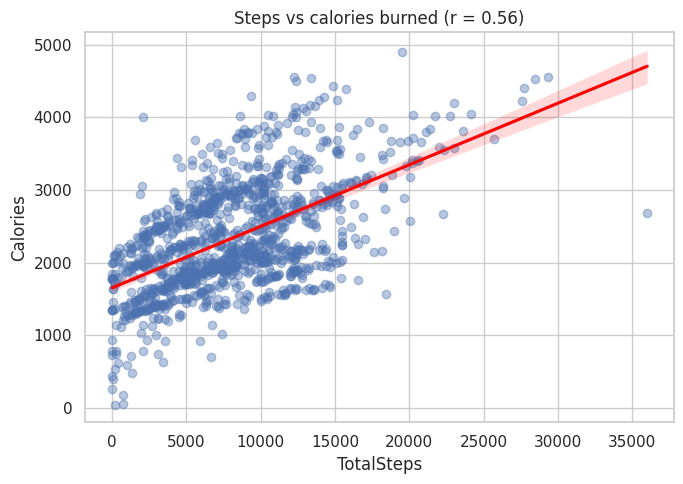

In [14]:
d = pd.read_sql("SELECT TotalSteps, Calories FROM daily_activity WHERE LikelyNotWorn = 0", conn)
r = d["TotalSteps"].corr(d["Calories"])
print("Correlation:", round(r, 2))

plt.figure(figsize=(7,5))
sns.regplot(data=d, x="TotalSteps", y="Calories",
            scatter_kws={"alpha":0.4}, line_kws={"color":"red"})
plt.title(f"Steps vs calories burned (r = {r:.2f})")
plt.tight_layout(); plt.savefig("steps_vs_calories.png", dpi=150); plt.show()

In [15]:
from google.colab import files
for f in ["weekly_active_users.png","steps_by_day.png","steps_by_hour.png",
          "user_segments.png","steps_vs_calories.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>